# 03 Predicting purchases without an SMS

**Project question.** With a limited marketing budget, which customers should receive an SMS so that it creates the most additional purchases?

**This notebook.** The usual way to choose whom to contact is to target clients who are likely to buy. This notebook builds that benchmark: a model of who buys *without* an SMS, trained on the control group only.

**Summary.** A gradient boosting model predicts who buys without an SMS with an AUC of 0.78, and its probabilities are well calibrated. A simple rule, the number of visits in the last 30 days, already reaches 0.75, so most of the predictable signal is shopping habit. These probabilities define the "contact likely buyers" policy that uplift targeting has to beat in notebook 06.

**Research question.** How well can we predict who buys without an SMS?

In [1]:
import json

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import roc_auc_score
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import PredefinedSplit, RandomizedSearchCV, cross_val_score

from x5uplift import plotting as P
from x5uplift.config import FEATURE_GROUPS_PATH, PROPENSITY_PATH, SEED
from x5uplift.modeling import bootstrap_ci, cross_fit_predict, load_experiment, model_matrix

pd.set_option("display.width", 140)
P.set_style()

## 1. Data

Models are fitted on control clients in the five training folds and predict every client of the held out fold. The test set (30%) is not used here.

In [2]:
exp = load_experiment()
feature_cols = [c for cols in json.loads(FEATURE_GROUPS_PATH.read_text()).values() for c in cols]
X = model_matrix(exp, feature_cols)
y = exp["target"]
in_train = exp["fold"] >= 0          # fold -1 is the untouched test set
is_control = exp["treatment_flg"] == 0

pd.Series({
    "features": X.shape[1],
    "control clients in training folds": int((in_train & is_control).sum()),
    "purchase rate among them": round(y[in_train & is_control].mean(), 4),
})

features                                54.0000
control clients in training folds    70041.0000
purchase rate among them                 0.6033
dtype: float64

In [3]:
X.isna().mean().loc[lambda s: s > 0].sort_values(ascending=False).mul(100).round(2).to_frame("pct_missing")

,pct_missing
days_since_first_redeem,20.07
days_issue_to_redeem,20.07
std_gap_days,4.65
std_basket_spend,1.91
mean_gap_days,1.91
overdue_ratio,1.91
age,0.44
share_cat_01,0.03
share_cat_02,0.03
share_cat_03,0.03


**Missing values mean "not applicable", not "unknown".** Redemption timing is empty for clients who never redeemed before the decision moment (20%), gap features for clients with one or two baskets (2% to 5%), and category shares when item amounts sum to zero. Only age is truly unknown. Gradient boosting handles missing values natively. Logistic regression gets median filling plus an indicator column per filled feature. Model based imputation is not used, because it would invent values for events that never happened.

## 2. Models

In [4]:
models = {
    "Logistic regression": lambda: make_pipeline(
        SimpleImputer(strategy="median", add_indicator=True), StandardScaler(), LogisticRegression(max_iter=2000)),
    "Gradient boosting": lambda: HistGradientBoostingClassifier(
        learning_rate=0.05, max_iter=300, early_stopping=True, random_state=SEED),
}
oof = {name: cross_fit_predict(make, X, y, exp["fold"], is_control) for name, make in models.items()}
oof["Rule: baskets in last 30 days"] = exp["n_baskets_recent"].to_numpy(dtype=float)  # no model

In [5]:
eval_rows = (in_train & is_control).to_numpy()   # purchase without an SMS is only observed in control
y_eval = y.to_numpy()[eval_rows]

rows = {}
for name, pred in oof.items():
    auc, lo, hi = bootstrap_ci(roc_auc_score, y_eval, pred[eval_rows])
    rows[name] = {"AUC": auc, "CI low": lo, "CI high": hi}

both = np.column_stack([oof["Gradient boosting"][eval_rows], oof["Logistic regression"][eval_rows]])
d, lo, hi = bootstrap_ci(lambda t, s: roc_auc_score(t, s[:, 0]) - roc_auc_score(t, s[:, 1]), y_eval, both)
print(f"Gradient boosting minus logistic regression: {d:+.4f} AUC (95% CI {lo:+.4f} to {hi:+.4f})")
pd.DataFrame(rows).T.round(4)

Gradient boosting minus logistic regression: +0.0052 AUC (95% CI +0.0042 to +0.0063)


,AUC,CI low,CI high
Logistic regression,0.7763,0.7729,0.7799
Gradient boosting,0.7815,0.7785,0.7848
Rule: baskets in last 30 days,0.7537,0.7503,0.7571


The rule alone reaches an AUC of 0.754: in grocery, clients who came often recently keep coming. The models add about 0.02 to 0.03 on top. Gradient boosting beats logistic regression by 0.005 (95% CI 0.004 to 0.006, paired bootstrap): a real but small gain. Gradient boosting is kept as the benchmark model.

**Small tuning check.** Eight random settings out of a grid of 24 are compared on the same folds. The rule, fixed before looking: switch only if the gain is at least 0.002 AUC.

In [6]:
fit_rows = in_train & is_control
cv = PredefinedSplit(exp.loc[fit_rows, "fold"])  # the same 5 folds as before

current = cross_val_score(
    HistGradientBoostingClassifier(learning_rate=0.05, max_iter=300, early_stopping=True, random_state=SEED),
    X[fit_rows], y[fit_rows], cv=cv, scoring="roc_auc")

search = RandomizedSearchCV(
    HistGradientBoostingClassifier(max_iter=500, early_stopping=True, random_state=SEED),
    param_distributions={
        "learning_rate": [0.05, 0.1],
        "max_leaf_nodes": [15, 31, 63],
        "min_samples_leaf": [20, 200],
        "l2_regularization": [0.0, 1.0],
    },
    n_iter=8, scoring="roc_auc", cv=cv, random_state=SEED,
)
search.fit(X[fit_rows], y[fit_rows])

print(f"Current setting: AUC {current.mean():.4f} (fold std {current.std():.4f})")
print(f"Best setting:    AUC {search.best_score_:.4f}, gain {search.best_score_ - current.mean():+.4f}")
search.best_params_

Current setting: AUC 0.7816 (fold std 0.0016)
Best setting:    AUC 0.7821, gain +0.0005


{'min_samples_leaf': 200,
 'max_leaf_nodes': 15,
 'learning_rate': 0.05,
 'l2_regularization': 0.0}

The best setting gains 0.0005 AUC, a third of the variation between folds (0.0016) and far below the 0.002 threshold, so the current setting is kept. Model settings are not what limits this prediction.

## 3. Calibration

The probabilities are used directly in the profit calculation of notebook 06, so they must be right, not only well ranked.


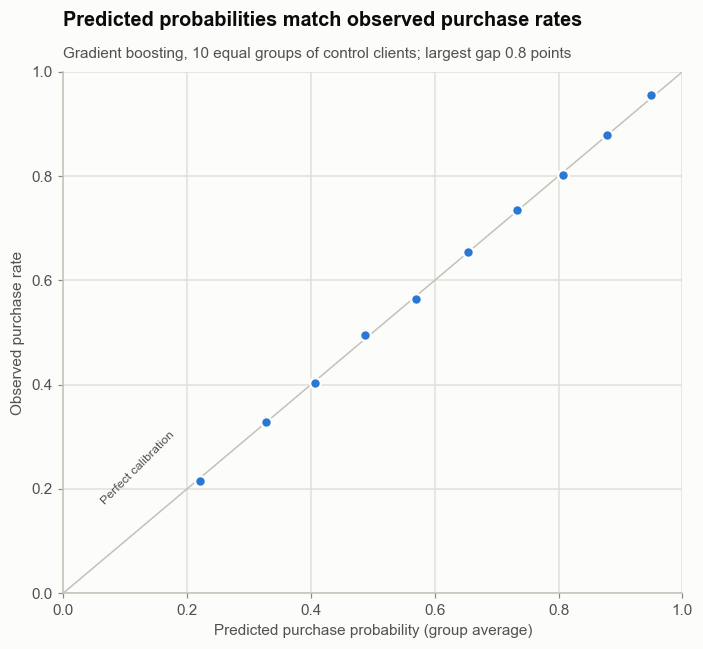

Brier score: 0.1847


In [7]:
p = oof["Gradient boosting"][eval_rows]
cal = pd.DataFrame({"predicted": p, "observed": y_eval, "bin": pd.qcut(p, 10, labels=False)}).groupby("bin").agg(
    predicted=("predicted", "mean"), observed=("observed", "mean"), n=("observed", "size"))
ci = 1.96 * np.sqrt(cal["observed"] * (1 - cal["observed"]) / cal["n"])
max_gap = (cal["observed"] - cal["predicted"]).abs().max()

fig, ax = plt.subplots(figsize=(6.5, 6))
ax.plot([0, 1], [0, 1], color=P.AXIS, linewidth=1)
ax.errorbar(cal["predicted"], cal["observed"], yerr=ci, fmt="o", color=P.BLUE, markersize=7,
            markeredgecolor=P.SURFACE, markeredgewidth=1.5, linewidth=1.5)
ax.text(0.12, 0.17, "Perfect calibration", rotation=45, fontsize=8, color=P.INK_2, ha="center")
ax.set(xlim=(0, 1), ylim=(0, 1), xlabel="Predicted purchase probability (group average)", ylabel="Observed purchase rate")
ax.grid(axis="x", visible=True)
verdict = "match" if max_gap < 0.03 else "deviate from"
P.titles(ax, f"Predicted probabilities {verdict} observed purchase rates",
         f"Gradient boosting, 10 equal groups of control clients; largest gap {max_gap * 100:.1f} points")
fig.tight_layout()
P.save(fig, "03_calibration")
plt.show()
print(f"Brier score: {np.mean((p - y_eval) ** 2):.4f}")

Across ten groups from 22% to 95% predicted probability, the largest gap to the observed rate is 0.8 points (Brier score 0.185). No recalibration is needed.

## 4. Saving the probabilities

Training folds keep their out of fold predictions. The test set gets predictions from one model fitted on all training fold controls; these predictions are only evaluated in notebook 06.

In [8]:
fit_rows = in_train & is_control
final = models["Gradient boosting"]().fit(X[fit_rows], y[fit_rows])

test = (~in_train).to_numpy()
propensity = oof["Gradient boosting"].copy()
propensity[test] = final.predict_proba(X[test])[:, 1]
assert not np.isnan(propensity).any()

out = pd.DataFrame({"client_id": exp["client_id"], "p_buy_without_sms": propensity})
out.to_parquet(PROPENSITY_PATH, index=False)
out.groupby(np.where(test, "test set", "training folds"))["p_buy_without_sms"].describe().round(3)

,count,mean,std,min,25%,50%,75%,max
test set,60012.0,0.604,0.230,0.092,0.406,0.612,0.806,0.978
training folds,140027.0,0.604,0.232,0.059,0.407,0.613,0.807,0.983


Both parts have the same distribution (mean 0.604), so the final model behaves like the fold models.

## 5. Why there is no lifetime value or churn model

Every client's **last** purchase falls in the three weeks before the decision moment, because X5 selected recently active clients (notebook 02). Clients who shopped earlier and then stopped are not in the data. A churn label (stopped buying) would therefore be zero for everyone, and a spend model for the last month would never see a client who spent nothing. Both would describe active clients only, so neither is built.

## Conclusion

**Answer.** Purchase without an SMS is predictable (AUC 0.78) and the probabilities are well calibrated, but most of the signal is habit: one simple frequency rule gets 0.75.

**What we learned**
* Likely buyers are easy to find. The open question for notebooks 04 to 06 is whether contacting them changes anything, or whether they would buy anyway.
* * Gradient boosting is only slightly better than logistic regression, and tuning adds nothing (+0.0005 AUC).

**What did not work or stays open**
* Lifetime value and churn cannot be modelled with this selection of clients.
* The time window behind `target` is unknown, so "probability of buying" refers to that unknown window.

**Next step.** Notebook 04 measures the effect of the SMS in the A/B test.